# 1. Dataset Overview

### **Target:** SalePrice  
### **Source:** [Ames Housing Dataset](https://www.openml.org/search?type=data&status=active&id=42165)  
### **Task:** Predict the market value of a home using 79 explanatory variables.

---

## High-Level Rubric

| Criteria                     | Points | Expectation                                                                                                                          |
|------------------------------|--------|-----------------------------------------------------------------------------------------------------------------------------|
| Data Cleaning                | 5      | Successful handling of all null values without crashing the notebook.                                                       |
| Data Visualization           | 5      | Correct generation of the correlation heatmap, target distribution, and feature scatter plots to illustrate data patterns   |
| Feature Engineering          | 10     | Creation of 3 representative features and correct application of required transformation if required.                       |
| Pipeline Logic               | 10     | Correct use of ColumnTransformer to automate preprocessing.                                                                 |
| Model Selection              | 10     | Implementation of all three models (Linear, Ridge, Lasso) with CV scores.                                                   |
| Evaluation and Diagnostics   | 10     | High-quality residual plot and final MSE/RMSE report on the test set.                                                       |

## Detailed Scoring Rubric

| Section                     | Task / Requirement           | Points | Criteria for Obtaining Points                                                                                   |
| --------------------------- | --------------------------- | ------ | --------------------------------------------------------------------------------------------------------------- |
| 2. Data Acquisition & Cleaning | Dataset Loading            | 3      | Successfully loads the dataset using `fetch_openml` or provided source and identifies null values.             |
|                             | Data Imputation & Dropout   | 2      | Correct implementation of the dropout strategy for sparse columns (>40% missing) and appropriate imputation (Median for numerical, Constant for categorical). |
| 3. Data Visualization       | Correlation Heatmap          | 1      | Correlation heatmap generated for numerical variables.                                                          |
|                             | Target Distribution         | 1      | Distribution plot (Histogram + KDE) for the target variable `SalePrice`.                                        |
|                             | Top Feature Scatter Plots   | 1      | Scatter plots for the top three features most correlated with the target.                                      |
|                             | Numerical Feature Histograms | 1      | Histograms for at least six numerical features to check for skewness.                                          |
|                             | Plot Styling & Labels       | 1      | All plots include clear axis labels, informative titles, and proper figure sizing.                              |
| 4. Feature Engineering      | New Feature Creation        | 6      | Successful creation of 3 new representative features (2 pts each) that provide logical insights into house value. |
|                             | Feature Transformations     | 4      | Correct application of required mathematical transformations to features identified as highly skewed.         |
| 5. Pipeline & Preprocessing | Feature Separation          | 5      | Correct identification and separation of numerical vs. categorical features for processing.                     |
|                             | ColumnTransformer Setup     | 5      | Use of `ColumnTransformer` to automate scaling (e.g., `StandardScaler`) and encoding (e.g., `OneHotEncoder`) without data leakage. |
| 6. Model Selection & Training | Model Implementation       | 6      | Successful implementation and training of all three required models: Linear Regression, Ridge, and Lasso (2 pts each). |
|                             | Cross-Validation Reporting  | 4      | Reporting of Cross-Validation (CV) scores for all three models to demonstrate generalization.                  |
| 7. Evaluation & Diagnostics | Test Set Evaluation         | 5      | Final evaluation on the test set reporting both Mean Squared Error (MSE) and Root Mean Squared Error (RMSE).   |
|                             | Residual Analysis           | 5      | Generation of a high-quality Residual Plot (Residuals vs. Predictions) with a clear reference line at zero and an analysis of the error pattern. |
| **TOTAL**                   |                             | **50** |                                                                                                                 |


---

## **Important Note:** 
While you should follow these guidelines as a foundational roadmap for your project, you are highly encouraged to go beyond the specific requirements. Feel free to implement your own creative ideas, explore additional feature engineering, test alternative algorithms, or apply advanced optimization techniques to improve your final results and insights.

---

# 2. Data Acquisition and Null Handling

- **Expected Action:**   
Load the dataset and identify columns with missing data. You must implement a strategy to fill these gaps (imputation) or drop columns that are too sparse (e.g., >40% missing).

Load the Ames Housing dataset using one of the following:
- The provided local `.arff` file
- Check out the documentation and use the sklearn.datasets.fetch_openml(name="house_prices", as_frame=True)
- The provided OpenML URL

Ensure column names and data types are preserved.

- **Key Requirement:**   
Use SimpleImputer for numerical columns (Median) and a Constant imputer for categorical ones.

In [1]:
# Task: Load data and handle null values
import pandas as pd
import numpy as np
import re
from io import StringIO
from sklearn.datasets import fetch_openml

# -----------------------------
# 1) Load the Ames Housing data
# -----------------------------
# Option A (recommended for this assignment): local ARFF file next to this notebook.
DATA_PATH = "asn_01_regression_data2.arff"  # <-- change if your file is elsewhere

def load_arff_as_dataframe(filepath: str) -> pd.DataFrame:
    '''
    Minimal ARFF loader that supports STRING/INTEGER/REAL and '?' missing values.
    (SciPy's loadarff doesn't support STRING attributes reliably.)
    '''
    cols, types, data_lines = [], [], []
    in_data = False

    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith("%"):
                continue

            if line.upper().startswith("@ATTRIBUTE"):
                m = re.match(r"@ATTRIBUTE\s+([^\s]+)\s+(.+)", line, re.IGNORECASE)
                if m:
                    name = m.group(1)
                    t = m.group(2).strip()
                    cols.append(name)
                    types.append(t)

            elif line.upper().startswith("@DATA"):
                in_data = True

            elif in_data:
                data_lines.append(line)

    df = pd.read_csv(
        StringIO("\n".join(data_lines)),
        header=None,
        names=cols,
        na_values=["?"],
        keep_default_na=True,
    )

    # Cast numeric columns and keep categoricals as dtype=object
    for name, t in zip(cols, types):
        if t.upper() in ("INTEGER", "REAL", "NUMERIC"):
            df[name] = pd.to_numeric(df[name], errors="coerce")
        else:
            # IMPORTANT: keep categoricals as object (sklearn SimpleImputer can error with pandas "string" dtype)
            df[name] = df[name].astype(object)

    return df

try:
    df = load_arff_as_dataframe(DATA_PATH)
    print(f"✅ Loaded local ARFF: {DATA_PATH} | shape={df.shape}")
except FileNotFoundError:
    # Option B: load from OpenML (requires internet on your machine)
    print("⚠️ Local ARFF not found. Trying OpenML instead...")
    housing = fetch_openml(name="house_prices", as_frame=True)
    df = housing.frame
    print(f"✅ Loaded from OpenML | shape={df.shape}")

# Ensure target is numeric
df["SalePrice"] = pd.to_numeric(df["SalePrice"], errors="coerce")

print("\nColumn count:", df.shape[1])
print("Target missing values:", df["SalePrice"].isna().sum())

# -----------------------------
# 2) Missing-value report
# -----------------------------
missing_count = df.isna().sum().sort_values(ascending=False)
missing_rate = (df.isna().mean() * 100).sort_values(ascending=False)

missing_report = pd.DataFrame(
    {"missing_count": missing_count, "missing_pct": missing_rate}
)

# Show the top 20 most-missing columns
display(missing_report.head(20))

# -----------------------------
# 3) Dropout strategy (>40% missing)
# -----------------------------
SPARSE_THRESHOLD = 40.0  # percent
sparse_cols = missing_report.index[missing_report["missing_pct"] > SPARSE_THRESHOLD].tolist()

print(f"\nDropping {len(sparse_cols)} columns with >{SPARSE_THRESHOLD:.0f}% missing:")
print(sparse_cols)

df = df.drop(columns=sparse_cols)

# Define X/y (NO manual imputation here; we impute in the pipeline later)
y = df["SalePrice"].copy()
X = df.drop(columns=["SalePrice"])

# Convert any pandas string/category to object (stability with sklearn)
for c in X.select_dtypes(include=["string", "category"]).columns:
    X[c] = X[c].astype(object)

print("\nAfter dropping sparse columns:")
print("X shape:", X.shape, "| y shape:", y.shape)


✅ Loaded local ARFF: asn_01_regression_data2.arff | shape=(1460, 81)

Column count: 81
Target missing values: 0


,missing_count,missing_pct
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageYrBlt,81,5.547945
GarageCond,81,5.547945
GarageType,81,5.547945



Dropping 6 columns with >40% missing:
['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu']

After dropping sparse columns:
X shape: (1460, 74) | y shape: (1460,)


# 3. Data Visualization

### Expected Action

 - Generate four specific types of visualizations to uncover patterns, identify outliers, and detect skewness.
 - The code must produce clear, labeled plots that would allow a developer to make informed decisions about feature selection and transformation.

### Visualization Quality Requirements:
- Clear axis labels
- Informative titles
- Appropriate figure size
- Legends where applicable
- Readable color contrast
- Proper tick formatting


### Required Tasks

- **Correlation Heatmap**  
  Compute the correlation matrix for all numerical variables and plot it as a heatmap.

- **Target Distribution**  
  Plot the distribution (histogram + KDE) of `SalePrice` to determine if the target variable is normally distributed or skewed.

- **High-Impact Relationships**  
  Create scatter plots for the top three features most highly correlated with `SalePrice`.

- **Skewness Audit**  
  Plot histograms for at least six other numerical features to identify which ones require log-transformation in the next section.

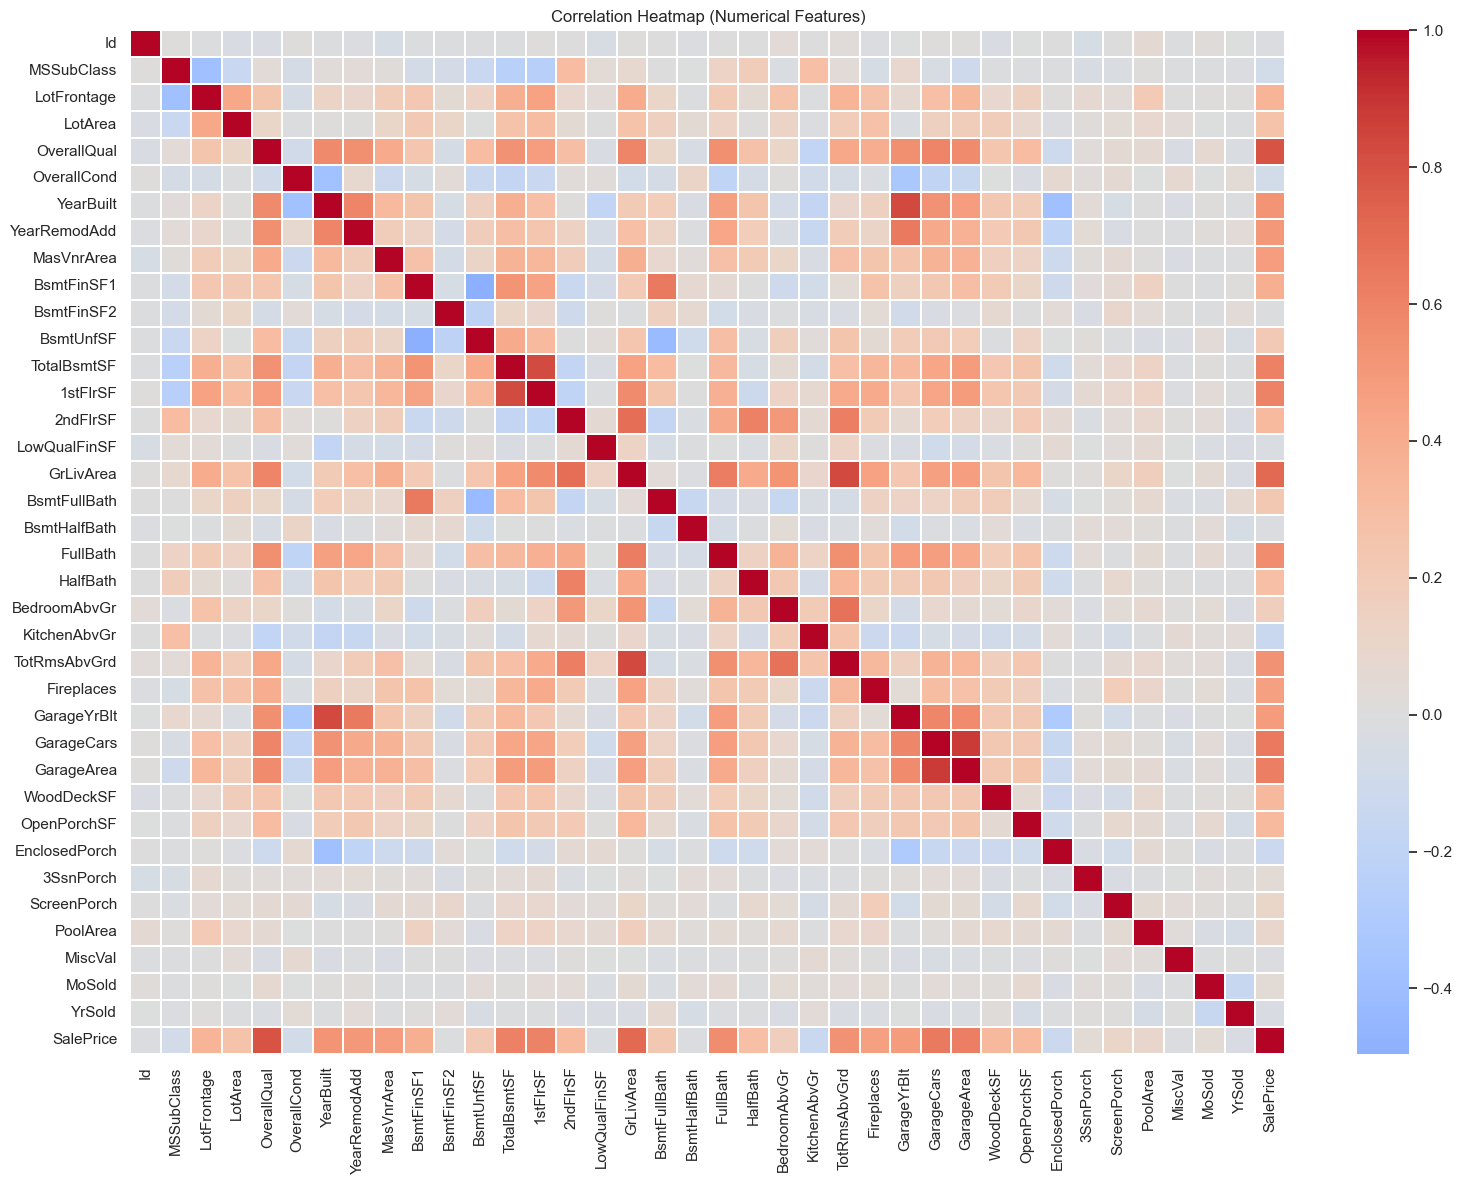


Top 10 numerical features correlated with SalePrice:


,abs_corr_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


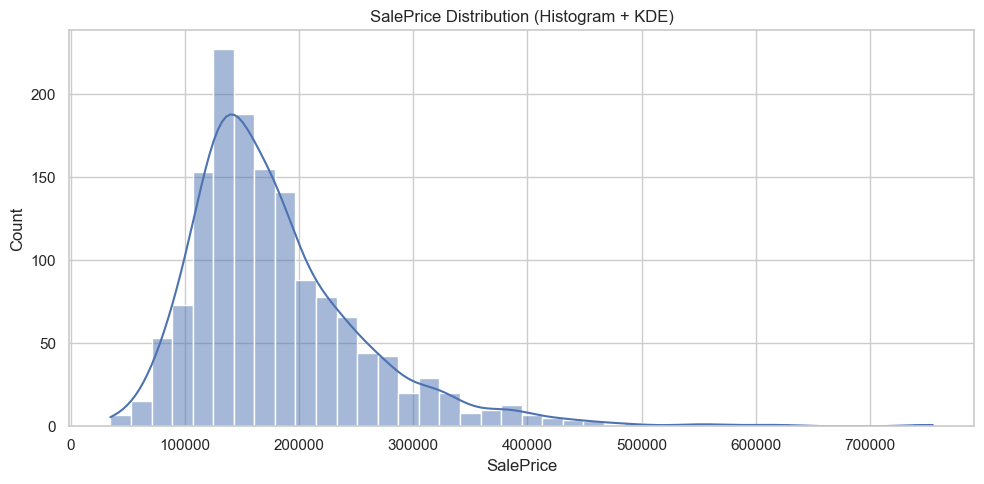

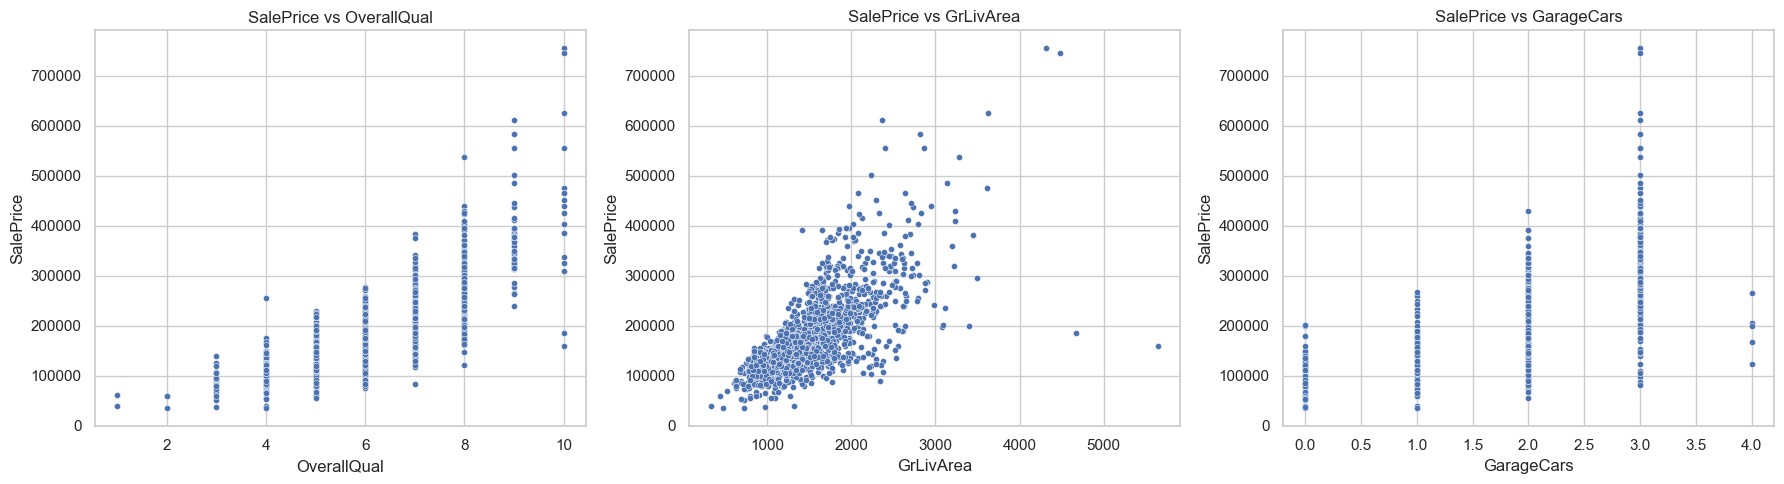

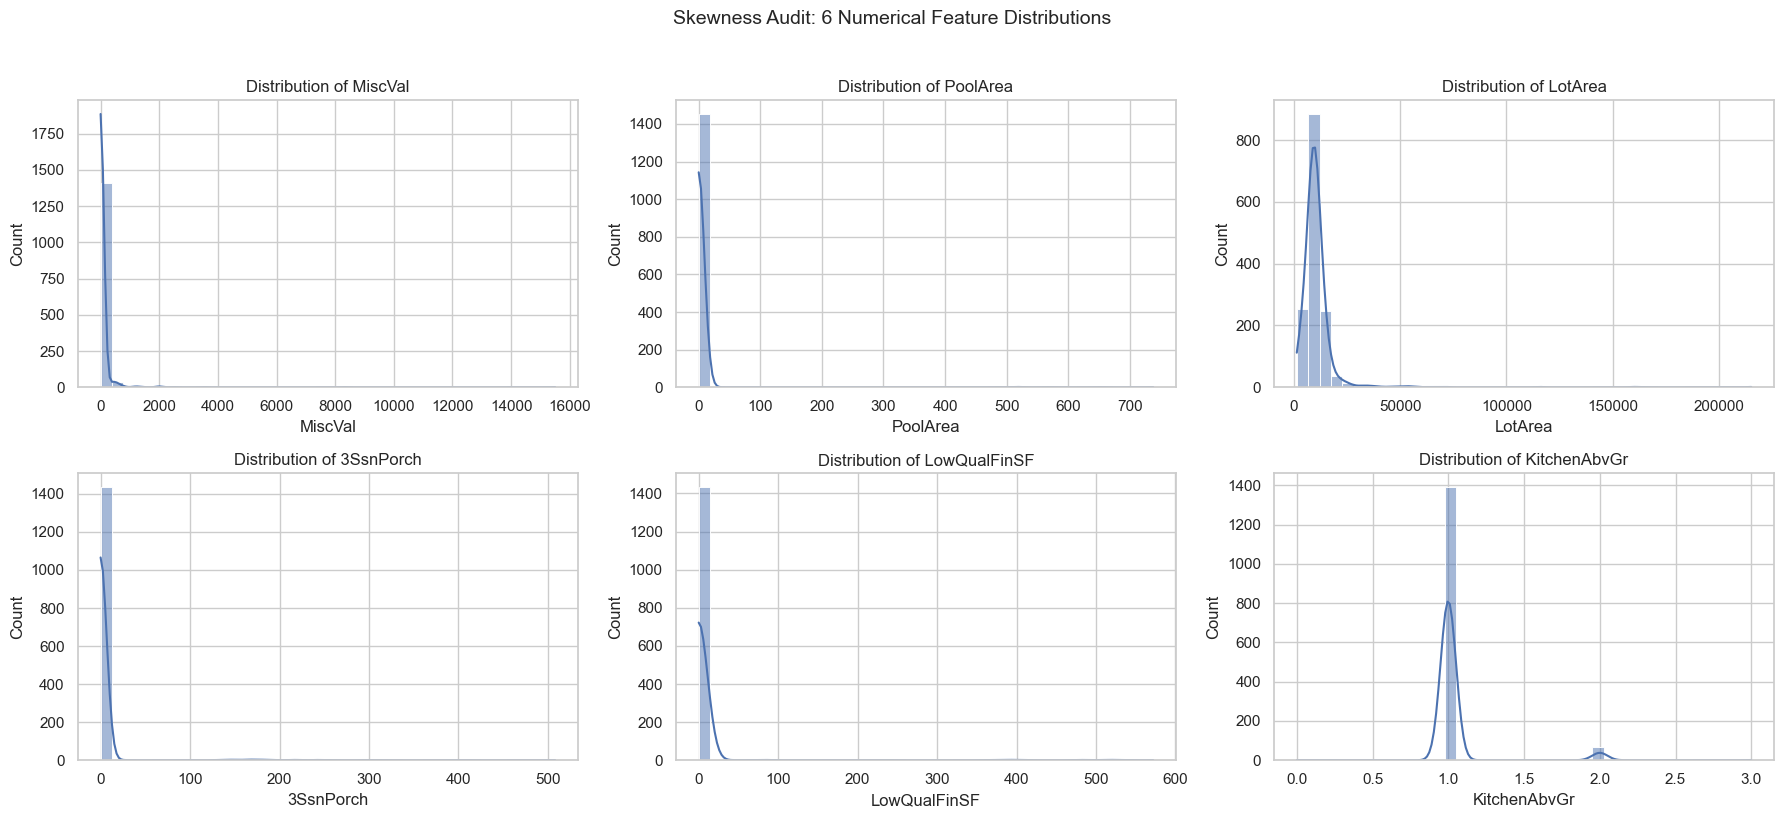

Skewness audit features: ['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'KitchenAbvGr']


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

# -----------------------------
# 1) Correlation Heatmap (numerical features)
# -----------------------------
num_df = df.select_dtypes(include=[np.number])

corr = num_df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(corr, center=0, cmap="coolwarm", linewidths=0.1)
plt.title("Correlation Heatmap (Numerical Features)")
plt.tight_layout()
plt.show()

# Also show top correlations with SalePrice (more readable than the full heatmap)
top_corr = (
    corr["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
)

print("\nTop 10 numerical features correlated with SalePrice:")
display(top_corr.head(10).to_frame("abs_corr_with_SalePrice"))

# -----------------------------
# 2) Target Distribution
# -----------------------------
plt.figure(figsize=(10, 5))
sns.histplot(df["SalePrice"], bins=40, kde=True)
plt.title("SalePrice Distribution (Histogram + KDE)")
plt.xlabel("SalePrice")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# -----------------------------
# 3) Scatter Plots for Top 3 Correlated Features
# -----------------------------
top3 = top_corr.head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, top3):
    sns.scatterplot(x=df[feat], y=df["SalePrice"], ax=ax, s=20)
    ax.set_title(f"SalePrice vs {feat}")
    ax.set_xlabel(feat)
    ax.set_ylabel("SalePrice")
plt.tight_layout()
plt.show()

# -----------------------------
# 4) Skewness Audit (at least 6 numerical features)
# -----------------------------
# Pick 6 high-skew candidates (or any 6 numerical features you want to inspect)
skew_candidates = (
    num_df.drop(columns=["SalePrice"], errors="ignore")
          .skew(numeric_only=True)
          .abs()
          .sort_values(ascending=False)
          .head(6)
          .index
          .tolist()
)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for ax, feat in zip(axes, skew_candidates):
    sns.histplot(df[feat], bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feat}")
    ax.set_xlabel(feat)
    ax.set_ylabel("Count")

plt.suptitle("Skewness Audit: 6 Numerical Feature Distributions", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

print("Skewness audit features:", skew_candidates)


# 4. Feature Engineering

### Expected Action
Create at least three new features that provide a better signal than raw counts.

Each engineered feature must satisfy at least one of the following:
- A ratio or interaction between two existing variables
- A domain-motivated transformation (e.g., price per square foot)
- A log-transformed or normalized version of a skewed feature
- A composite feature that captures house quality or size

---

### Briefly justify why each engineered feature is meaningful.   
### <font color=darkred> **Justifications:**<font> 

---

In [3]:
# Task: Feature creation and Log Transformations
import numpy as np

# ---------------------------------------------------
# Create 3+ engineered features (no manual imputation)
# ---------------------------------------------------
# Justifications (put these in your report):
# 1) TotalSF: total above + below grade area is often more predictive than any single floor area.
# 2) TotalBathrooms: combines full/half and basement baths into one "bathroom capacity" signal.
# 3) AgeAtSale: newer homes generally command higher prices; captures depreciation/modernity.
# (Optional) QualityIndex: interaction between OverallQual and OverallCond.

df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

df["TotalBathrooms"] = (
    df["FullBath"]
    + 0.5 * df["HalfBath"]
    + df["BsmtFullBath"]
    + 0.5 * df["BsmtHalfBath"]
)

df["AgeAtSale"] = df["YrSold"] - df["YearBuilt"]

# Optional 4th feature (nice to have)
df["QualityIndex"] = df["OverallQual"] * df["OverallCond"]

# Update X/y after feature engineering
y = df["SalePrice"].copy()
X = df.drop(columns=["SalePrice"])

# Convert any pandas string/category to object for sklearn stability
for c in X.select_dtypes(include=["string", "category"]).columns:
    X[c] = X[c].astype(object)

print("✅ Engineered features added:", ["TotalSF", "TotalBathrooms", "AgeAtSale", "QualityIndex"])
print("X shape after feature engineering:", X.shape)


✅ Engineered features added: ['TotalSF', 'TotalBathrooms', 'AgeAtSale', 'QualityIndex']
X shape after feature engineering: (1460, 78)


# 5. Building the Scikit-Learn Pipeline

- Split the dataset into training and test sets (e.g., 80/20).
- Fit all models using the training set only.
- Use the test set for final evaluation and diagnostics.


### Expected Action: 
Construct a `ColumnTransformer` that processes numerical and categorical features separately within a single execution pipeline. The components shown below are illustrative examples; alternative, equally valid preprocessing strategies may also be used.

- Identify columns with missing data.
- Do not impute manually here.
- Handle all imputation inside the ColumnTransformer pipeline.

---

- **Numerical Pipeline:**   Impute ---> Scale  (`StandardScaler`)
- **Categorical Pipeline:** Impute ---> Encode (`OneHotEncoder`)



In [4]:
# Task: Build a complete transformation pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
import numpy as np

# -----------------------------
# Train-test split (80/20)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Identify numerical vs categorical columns
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = [c for c in X_train.columns if c not in num_features]

print(f"Numeric features: {len(num_features)} | Categorical features: {len(cat_features)}")

# -----------------------------
# Identify skewed numerical features (based on TRAIN ONLY to avoid leakage)
# -----------------------------
tmp_num = X_train[num_features].copy()
tmp_num = tmp_num.fillna(tmp_num.median(numeric_only=True))

skewness = tmp_num.skew(numeric_only=True).abs().sort_values(ascending=False)

SKEW_THRESHOLD = 0.75
skewed_num_features = skewness[skewness > SKEW_THRESHOLD].index.tolist()

# Only log-transform features that are non-negative (log1p requires x >= 0)
skewed_num_features = [c for c in skewed_num_features if tmp_num[c].min() >= 0]

other_num_features = [c for c in num_features if c not in skewed_num_features]

print(f"Skewed numerical features to log1p (|skew|>{SKEW_THRESHOLD}): {len(skewed_num_features)}")
print("Example skewed features:", skewed_num_features[:10])

# -----------------------------
# Build pipelines
# -----------------------------
log_num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("log_num", log_num_pipeline, skewed_num_features),
        ("num", num_pipeline, other_num_features),
        ("cat", cat_pipeline, cat_features),
    ],
    remainder="drop"
)

print("✅ Preprocessor ready:", preprocessor)


Numeric features: 41 | Categorical features: 37
Skewed numerical features to log1p (|skew|>0.75): 22
Example skewed features: ['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'KitchenAbvGr', 'BsmtFinSF2', 'ScreenPorch', 'BsmtHalfBath', 'EnclosedPorch']
✅ Preprocessor ready: ColumnTransformer(transformers=[('log_num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log1p',
                                                  FunctionTransformer(func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch',
                                  'LowQualFinSF', 'KitchenAbvGr', 'BsmtFinSF2',
                                  'ScreenPorch', 'BsmtHalfBath',
                                  'EnclosedPorch', 'LotFront

# 6. Regularized Model

### Expected Action:
- **Train three different models:**   
    a standard Linear Regression, a Ridge model, and a Lasso model.  
    
- **Key Requirement:**   
    Use 5-fold cross-validation to report the Mean Squared Error (MSE/RMSE) for each.

In [5]:
# Task: Train and compare Linear, Ridge, and Lasso models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, KFold
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
import warnings

# 5-fold CV (shuffle=True makes folds more representative)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LinearRegression": LinearRegression(),
    "Ridge(alpha=10)": Ridge(alpha=10, random_state=42),
    # A slightly stronger alpha keeps runtime reasonable and avoids convergence warnings
    "Lasso(alpha=0.05)": Lasso(alpha=0.05, max_iter=2000, selection="random", random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model),
    ])

    # cross_val_score returns NEGATIVE MSE for this scoring metric
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        neg_mse_scores = cross_val_score(
            pipe, X_train, y_train,
            scoring="neg_mean_squared_error",
            cv=cv,
            n_jobs=-1  # use all CPU cores (optional)
        )

    rmse_scores = np.sqrt(-neg_mse_scores)

    rows.append({
        "model": name,
        "rmse_mean": rmse_scores.mean(),
        "rmse_std": rmse_scores.std(),
    })

cv_results = pd.DataFrame(rows).sort_values("rmse_mean")
display(cv_results)

best_model_name = cv_results.iloc[0]["model"]
print(f"✅ Best model by CV RMSE: {best_model_name}")


,model,rmse_mean,rmse_std
1,Ridge(alpha=10),29919.723033,4999.097922
2,Lasso(alpha=0.05),33387.235014,4602.772489
0,LinearRegression,33748.519947,4717.991902


✅ Best model by CV RMSE: Ridge(alpha=10)


# 7. Evaluation and Diagnostics

### Expected Action  
Evaluate the performance of your best-performing regression model using both **visual diagnostics** and **quantitative error metrics**.

- Select the best-performing model based on the **lowest cross-validated RMSE** (or MSE).  
- Retrain this model on the **full training set**.  
- Use this trained model to generate **predictions and residuals on the test set**.

---

## 1. Residual Analysis (Visual Diagnostic)

- Generate a **Predictions vs. Residuals** plot using the **test set**.  
- The plot must include:
  - A horizontal **reference line at y = 0**  
  - Clear **axis labels**  
  - A **descriptive title**  
- Inspect the plot for:
  - **Non-linear patterns** (indicating model misspecification)  
  - **Heteroscedasticity** (changing variance across predictions)  
  - **Systematic bias** (residuals consistently above or below zero)  

A high-quality residual plot should display residuals randomly scattered around zero with no visible structure.

---

## 2. Final Model Performance (Quantitative Metrics)

- Compute and report the following metrics on the **test set**:
  - **Mean Squared Error (MSE)**  
  - **Root Mean Squared Error (RMSE)**  
- Briefly interpret what these values imply about the model’s real-world prediction accuracy.

---

### Key Requirements (Rubric-Aligned)

- High-quality **Predictions vs. Residuals** plot on the **test set**  
- Final **MSE and RMSE** values reported on the **test set**  
- A short diagnostic interpretation linking residual behavior to model performance

Test MSE:  998,123,132.62
Test RMSE: 31,593.09


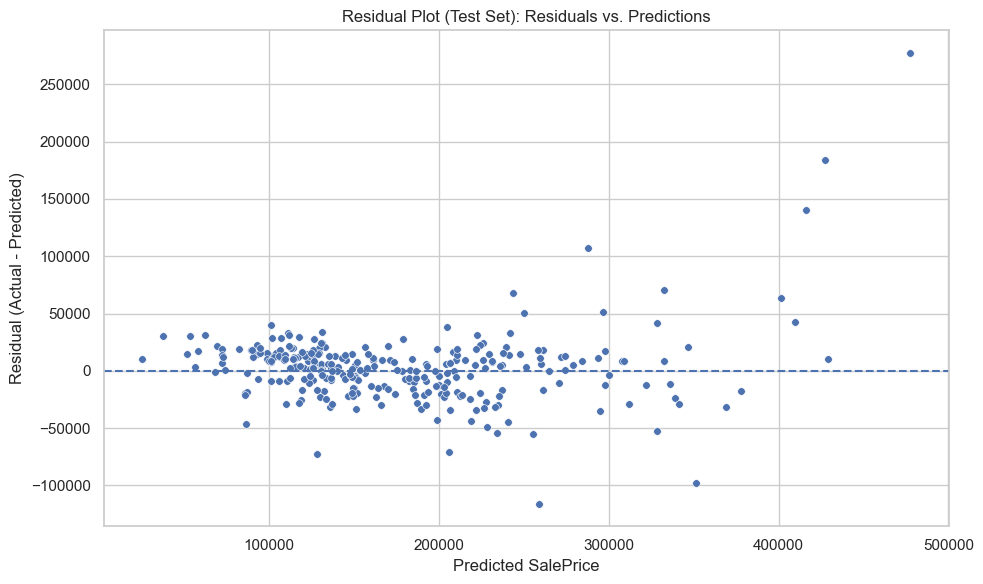

In [6]:
# Task: Plot residuals to evaluate the model
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Re-create the best model object from its name
model_lookup = {
    "LinearRegression": LinearRegression(),
    "Ridge(alpha=10)": Ridge(alpha=10, random_state=42),
    "Lasso(alpha=0.05)": Lasso(alpha=0.05, max_iter=2000, selection="random", random_state=42),
}

best_model = model_lookup[best_model_name]

best_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", best_model),
])

# Fit on the full training set
best_pipe.fit(X_train, y_train)

# Predict on test set
y_pred = best_pipe.predict(X_test)

# Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Test MSE:  {mse:,.2f}")
print(f"Test RMSE: {rmse:,.2f}")

# Residuals
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuals, s=30)
plt.axhline(0, linestyle="--")
plt.title("Residual Plot (Test Set): Residuals vs. Predictions")
plt.xlabel("Predicted SalePrice")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

# Quick diagnostic notes (write these in your report, based on what you see):
# - Random scatter around 0 is good.
# - Curves/patterns suggest non-linearity.
# - Funnel shape suggests heteroscedasticity.


# Additional Analysis or Notes (Optional)

Use this cell to add any further observations, insights, or notes regarding your model's performance, the feature engineering process, or any interesting patterns you discovered in the Ames Housing dataset.